# Copy this notebook into usr/ and adjust to your needs.

In [30]:
%load_ext autoreload
%autoreload 2
import warnings
warnings.filterwarnings('ignore')

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [31]:
### setup ###

import sys
# setup path to python virtual env & code directory
ecf_env_path = '/Users/kszczepaniak/Code/ecf-explorer-env'
lib_ecf_path = ecf_env_path + '/ecf-explorer/src'
sys.path.append(lib_ecf_path)

from utils.postprocess import load_clustering_results, select_reprseqs_to_display 
from utils.postprocess import load_features_data, select_features_to_display
from plots.plot_clustering_and_ecfs import plot_alignment_selected

workdir_path = '/Users/kszczepaniak/Data/Phage/phage-pp-workdir-ecftest-300'

In [32]:
# load dataset of hits with annotated clusters

clustering_results = load_clustering_results(workdir_path, mode='clusters')
clustering_results

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,cluster
0,reprseq30989,61,260,261,reprseq17791,43,198,200,19,108.2,1.200000e-12,98.7,1.900000e-16,0
1,reprseq30989,61,257,261,reprseq25394,60,214,215,16,115.8,1.700000e-13,98.9,2.700000e-17,0
2,reprseq30989,61,249,261,reprseq33575,43,210,217,16,70.4,2.200000e-06,96.7,3.400000e-10,0
3,reprseq30989,61,260,261,reprseq16961,43,216,218,15,108.0,2.000000e-12,98.7,3.200000e-16,0
4,reprseq30989,61,260,261,reprseq29975,45,231,233,12,107.4,3.400000e-12,98.6,5.500000e-16,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
652820,reprseq35525,5,480,488,reprseq31745,3,457,487,23,590.9,4.200000e-72,100.0,6.400000e-76,0
652821,reprseq35525,5,467,488,reprseq18132,2,527,527,23,1126.4,6.000000e-140,100.0,9.000000e-144,0
652822,reprseq35525,6,466,488,reprseq21544,3,475,476,42,985.6,4.000000e-123,100.0,6.000000e-127,0
652823,reprseq35525,7,418,488,reprseq29665,18,412,432,15,321.6,1.900000e-37,100.0,2.900000e-41,0


In [33]:
# load features data
features_to_load = ['hhblits-pfam', 'hhblits-uniclust', 'hhblits-phrogs', 'hhrepid']

features_data = load_features_data(workdir_path, features_to_load)
for fname, fdata in features_data.items():
    print(fname)
    display(fdata)

hhblits-pfam


,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,annot
0,reprseq06167,18,118,301,PF10127.9,14,100,249,18,47.5,0.00089,93.4,2.500000e-07,PF10127.9 ; RlaP ; RNA repair pathway DNA poly...
1,reprseq06167,24,53,301,PF01909.23,10,39,91,33,34.4,0.00620,89.7,1.900000e-06,PF01909.23 ; NTP_transf_2 ; Nucleotidyltransfe...
2,reprseq06167,28,53,301,PF14091.6,18,43,150,19,35.5,0.06400,78.6,1.700000e-05,PF14091.6 ; DUF4269 ; Domain of unknown functi...
3,reprseq06167,22,53,301,PF03445.13,47,78,139,22,32.8,0.07000,77.1,2.000000e-05,PF03445.13 ; DUF294 ; Putative nucleotidyltran...
4,reprseq06167,22,104,301,PF12633.7,88,158,197,15,31.5,1.20000,40.5,2.900000e-04,PF12633.7 ; Adenyl_cycl_N ; Adenylate cyclase ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
631722,reprseq20510,82,117,151,PF08326.12,40,87,743,19,28.5,4.10000,20.0,1.100000e-03,PF08326.12 ; ACC_central ; Acetyl-CoA carboxyl...
631723,reprseq35712,124,140,247,PF07460.11,3,19,37,47,38.8,0.00082,93.7,1.800000e-07,PF07460.11 ; NUMOD3 ; NUMOD3 motif (2 copies)
631724,reprseq35712,28,107,247,PF01541.24,2,86,86,22,37.5,0.00340,91.4,9.000000e-07,PF01541.24 ; GIY-YIG ; GIY-YIG catalytic domain
631725,reprseq09398,4,15,60,PF15103.6,45,56,103,42,22.9,2.50000,31.1,5.100000e-04,PF15103.6 ; G0-G1_switch_2 ; G0/G1 switch prot...


hhblits-uniclust


,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,annot
0,reprseq06167,1,301,301,UniRef100_A0A1L7N0U6,1,301,301,100,1208.9,4.000000e-182,100.0,1.000000e-187,UniRef100_A0A1L7N0U6 NTP_transf_2 domain-conta...
1,reprseq06167,4,101,301,UniRef100_A0A101VYF9,123,209,253,24,51.6,1.400000e-01,92.4,5.200000e-07,UniRef100_A0A101VYF9 Polbeta domain-containing...
2,reprseq06167,4,97,301,UniRef100_A0A068N1M9,54,130,168,30,48.1,1.100000e-01,92.4,5.300000e-07,UniRef100_A0A068N1M9 NTP_transf_2 domain-conta...
3,reprseq06167,6,102,301,UniRef100_A0A086YMT5,38,118,158,23,44.6,2.900000e-01,90.1,1.600000e-06,UniRef100_A0A086YMT5 NTP_transf_2 domain-conta...
4,reprseq06167,7,55,301,UniRef100_A0A081BYP5,24,72,137,31,45.0,5.900000e-01,89.8,1.800000e-06,UniRef100_A0A081BYP5 DNA polymerase beta domai...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8803284,reprseq03536,9,51,73,UniRef100_A0A349NMV3,37,78,111,29,24.4,2.100000e+02,29.7,5.600000e-04,UniRef100_A0A349NMV3 Uncharacterized protein (...
8803285,reprseq03536,21,69,73,UniRef100_UPI000DF4DABA,34,81,141,31,24.8,2.800000e+02,28.0,6.300000e-04,UniRef100_UPI000DF4DABA uncharacterized protei...
8803286,reprseq03536,31,67,73,UniRef100_A0A0G2FCC0,75,111,168,32,25.3,3.000000e+02,27.1,6.700000e-04,UniRef100_A0A0G2FCC0 Uncharacterized protein n...
8803287,reprseq03536,1,37,73,UniRef100_A0A124FI80,1,37,923,32,30.4,2.900000e+02,25.2,7.700000e-04,UniRef100_A0A124FI80 Oligosaccharyl transferas...


hhblits-phrogs


,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,annot
0,reprseq06167,1,301,301,phrog_34134,1,301,301,100,1208.9,9.000000e-184,100.0,1.000000e-187,phrog_34134 ## AP017925_p115
1,reprseq06167,21,116,301,phrog_388,5,79,252,27,40.2,9.800000e-02,79.0,1.600000e-05,phrog_388 ## NC_031245_p308
2,reprseq06167,16,72,301,phrog_14344,22,76,277,29,40.5,2.900000e-01,71.4,3.600000e-05,phrog_14344 ## MF805716_p92
3,reprseq06167,99,151,301,phrog_21551,51,105,109,32,29.6,4.000000e+00,32.6,4.700000e-04,phrog_21551 ## MG250483_p242
4,reprseq06167,256,276,301,phrog_1087,9,29,42,29,24.1,7.100000e+00,22.9,9.000000e-04,phrog_1087 ## KX657793_p9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
724130,reprseq09398,37,52,60,phrog_2844,22,39,40,38,20.2,4.800000e+00,30.3,5.400000e-04,phrog_2844 ## NC_028785_p88
724131,reprseq09398,40,52,60,phrog_9034,51,63,87,38,22.0,7.200000e+00,23.9,8.400000e-04,phrog_9034 ## MH045564_p31
724132,reprseq03536,15,64,73,phrog_18549,36,85,118,18,26.4,2.200000e+00,42.9,2.500000e-04,phrog_18549 ## MF448340_p290
724133,reprseq03536,12,37,73,phrog_17677,99,125,157,50,26.9,2.700000e+00,39.3,3.100000e-04,phrog_17677 ## NC_028829_p36


hhrepid


,qname,annot,type-pval,type-len,rep-id,prob,pval,rep-score,rep-score-norm,qstart,qend,sstart,send,rep-len,rep-offset,rep-seq
0,reprseq23453,A,3.700000e-30,104,A1,0.0,7.900000e-01,6.69,0.09,335,420,555,634,80,35,-AIDKIRKLLSIGFNQ.Aty.IVETKLYQLS..K..MSVQDLKdeI...
1,reprseq23453,A,3.700000e-30,104,A2,0.0,4.200000e-21,65.11,0.70,456,553,557,653,93,0,---NAYVFAKSTDEII.SgdtRGRKGQNFVP..S..TVKKVII..E...
2,reprseq23453,A,3.700000e-30,104,A3,0.0,9.900000e-30,74.36,0.71,554,657,554,657,104,0,VTEAGYMKRIPVDGFD.L...NRKAAVIAIK..P..TEGDILK..A...
3,reprseq23453,A,3.700000e-30,104,A4,0.0,8.000000e-23,68.60,0.82,658,746,558,642,84,0,----GKGKIIDLEEFPlR...RGDKGRRSMLkaItlAEGEMLI..G...
4,reprseq36738,A,5.600000e-11,66,A1,0.0,3.700000e-17,38.94,0.68,26,82,26,82,57,3,--DTQAATVLHAAVGIAGEVAELLVAS..........SIENLVEEM...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9309,reprseq12697,C,1.300000e-11,7,C3,0.0,3.500000e-05,1.82,0.26,172,178,186,192,7,7,TIKTQTSqlkadtq
9310,reprseq12697,C,1.300000e-11,7,C4,0.0,3.300000e-05,1.55,0.22,186,192,186,192,7,7,AIKDQTNqiktdtg
9311,reprseq12697,C,1.300000e-11,7,C5,0.0,9.500000e-06,1.84,0.26,200,206,186,192,7,0,VIRDEAN.......
9312,reprseq12697,C,1.300000e-11,7,C6,0.0,2.200000e-05,1.72,0.25,207,213,186,192,7,0,TAKEDAQ.......


In [63]:
# select representative proteins to display
reprseqs_to_display = [72, 30989, 22103]
# reprseqs_to_display = [3888, 11069, 12827, 12827, 14391, 17969, 36416, 227, 27906,
#                        21805, 24843, 33085]


# filter reprseq & features data for plot
selected_reprseq_data  = select_reprseqs_to_display(clustering_results, reprseqs_to_display)
selected_features_data = select_features_to_display(features_data, reprseqs_to_display)

# show selected
display(selected_reprseq_data)
print('FEATURES:')
for fname, fdata in selected_features_data.items():
    print(fname)
    display(fdata)

,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,cluster
0,reprseq30989,61,260,261,reprseq17791,43,198,200,19,108.2,1.200000e-12,98.7,1.900000e-16,0
1,reprseq30989,61,257,261,reprseq25394,60,214,215,16,115.8,1.700000e-13,98.9,2.700000e-17,0
2,reprseq30989,61,249,261,reprseq33575,43,210,217,16,70.4,2.200000e-06,96.7,3.400000e-10,0
3,reprseq30989,61,260,261,reprseq16961,43,216,218,15,108.0,2.000000e-12,98.7,3.200000e-16,0
4,reprseq30989,61,260,261,reprseq29975,45,231,233,12,107.4,3.400000e-12,98.6,5.500000e-16,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
647282,reprseq22103,783,819,869,reprseq20075,1446,1484,1887,26,71.2,1.100000e-02,90.7,1.300000e-06,1
647283,reprseq22103,783,792,869,reprseq05115,1279,1288,2127,50,107.2,1.000000e-07,97.4,1.200000e-11,1
647284,reprseq22103,786,822,869,reprseq18746,937,973,1022,33,60.9,1.200000e-02,90.6,1.300000e-06,1
647285,reprseq22103,828,862,869,reprseq07400,935,969,970,23,130.9,3.800000e-10,98.2,4.300000e-14,1


FEATURES:
hhblits-pfam


,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,annot
383159,reprseq22103,208,350,869,PF10145.9,8,150,192,16,73.4,0.000004,96.6,6.800000e-10,PF10145.9 ; PhageMin_Tail ; Phage-related mino...
383160,reprseq22103,54,83,869,PF15254.6,426,455,850,23,70.3,0.000350,94.7,6.100000e-08,PF15254.6 ; CCDC14 ; Coiled-coil domain-contai...
383161,reprseq22103,49,81,869,PF15967.5,286,318,605,21,65.1,0.001400,93.4,2.400000e-07,PF15967.5 ; Nucleoporin_FG2 ; Nucleoporin FG r...
383162,reprseq22103,171,180,869,PF09726.9,510,519,659,10,65.4,0.001800,93.1,3.100000e-07,PF09726.9 ; Macoilin ; Macoilin family
383163,reprseq22103,50,85,869,PF06785.11,132,167,222,6,52.5,0.004200,91.8,7.400000e-07,PF06785.11 ; UPF0242 ; Uncharacterised protein...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
477751,reprseq00072,172,195,210,PF06249.12,110,133,148,21,24.0,4.800000,22.0,9.700000e-04,PF06249.12 ; EutQ ; Ethanolamine utilisation p...
477752,reprseq00072,171,194,210,PF07385.12,152,175,221,21,26.3,5.500000,20.7,1.100000e-03,PF07385.12 ; Lyx_isomer ; D-lyxose isomerase
477753,reprseq00072,105,194,210,PF16867.5,98,158,164,11,24.2,5.600000,20.1,1.100000e-03,PF16867.5 ; DMSP_lyase ; Dimethlysulfoniopropr...
612161,reprseq30989,3,79,261,PF01541.24,1,77,86,23,41.4,0.000610,93.9,1.600000e-07,PF01541.24 ; GIY-YIG ; GIY-YIG catalytic domain


hhblits-uniclust


,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,annot
5398375,reprseq22103,1,596,869,UniRef100_A0A0U5K0A9,2,604,1174,23,693.2,9.400000e-85,100.0,2.100000e-90,UniRef100_A0A0U5K0A9 Phage-related minor tail ...
5398376,reprseq22103,1,586,869,UniRef100_A0A0R2DDY7,215,795,1385,25,692.3,9.400000e-84,100.0,2.100000e-89,UniRef100_A0A0R2DDY7 PhageMin_Tail domain-cont...
5398377,reprseq22103,1,823,869,UniRef100_A0A0J6WRI9,1,896,958,23,646.6,4.000000e-80,100.0,8.900000e-86,UniRef100_A0A0J6WRI9 PhageMin_Tail domain-cont...
5398378,reprseq22103,1,602,869,UniRef100_A0A099I5C4,31,611,1009,24,654.0,1.800000e-78,100.0,4.000000e-84,UniRef100_A0A099I5C4 Phage tail length tape me...
5398379,reprseq22103,1,736,869,UniRef100_A0A077UMP1,338,1144,2010,19,573.5,8.300000e-65,100.0,1.800000e-70,UniRef100_A0A077UMP1 Lysostaphin n=1 Tax=Staph...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8545131,reprseq30989,85,122,261,UniRef100_R5HIE1,15,52,344,24,35.1,1.200000e+02,42.1,2.600000e-04,UniRef100_R5HIE1 Uncharacterized protein n=1 T...
8545132,reprseq30989,40,100,261,UniRef100_A0A074KNW4,436,494,545,22,37.5,1.100000e+02,41.9,2.700000e-04,UniRef100_A0A074KNW4 Thioredoxin domain-contai...
8545133,reprseq30989,36,172,261,UniRef100_M1H3N7,138,274,406,17,36.1,1.100000e+02,41.8,2.700000e-04,UniRef100_M1H3N7 GIY-YIG catalytic domain-cont...
8545134,reprseq30989,35,62,261,UniRef100_A0A1N5V964,133,160,229,29,34.5,9.700000e+01,41.0,2.800000e-04,UniRef100_A0A1N5V964 Uroporphyrinogen-III synt...


hhblits-phrogs


,qname,qstart,qend,qlength,sname,sstart,send,slength,pident,bitscore,eval,prob,pval,annot
440922,reprseq22103,1,820,869,phrog_991,1,709,767,25,493.0,3.700000e-57,100.0,4.100000e-61,phrog_991 ## p290120 VI_00584
440923,reprseq22103,1,510,869,phrog_4704,4,508,576,19,390.7,7.400000e-50,100.0,8.200000e-54,phrog_4704 ## p73956 VI_01292
440924,reprseq22103,1,528,869,phrog_1293,3,527,1391,19,412.0,3.900000e-46,100.0,4.300000e-50,phrog_1293 ## p160953 VI_04898
440925,reprseq22103,6,567,869,phrog_5218,3,544,1296,16,333.4,1.900000e-37,100.0,2.100000e-41,phrog_5218 ## p362597 VI_05060
440926,reprseq22103,136,596,869,phrog_1272,28,506,878,17,320.9,2.400000e-36,100.0,2.600000e-40,phrog_1272 ## p177841 VI_05919
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
702691,reprseq30989,3,125,261,phrog_7168,1,122,223,15,51.0,5.800000e-03,91.8,7.200000e-07,phrog_7168 ## MF001361_p151
702692,reprseq30989,230,255,261,phrog_26163,13,35,39,26,36.0,1.600000e-02,89.8,1.800000e-06,phrog_26163 ## KY942056_p65
702693,reprseq30989,4,88,261,phrog_24132,137,237,242,13,40.7,2.500000e-01,73.5,3.000000e-05,phrog_24132 ## MF042360_p422
702694,reprseq30989,3,96,261,phrog_10820,2,100,205,26,32.5,3.900000e+00,33.0,4.600000e-04,phrog_10820 ## NC_028847_p60


hhrepid


,qname,annot,type-pval,type-len,rep-id,prob,pval,rep-score,rep-score-norm,qstart,qend,sstart,send,rep-len,rep-offset,rep-seq
3070,reprseq22103,A,3.100000e-51,21,A1,0.0,0.012000,4.30,0.21,167,186,265,284,20,0,-SSVDFESSIAGVAKTFPGTQ.................
3071,reprseq22103,A,3.100000e-51,21,A2,0.0,0.002400,5.61,0.27,187,207,264,284,21,17,EQLHKTTNEIRKMAKEIPASTqeisavaeaagqlgies
3072,reprseq22103,A,3.100000e-51,21,A3,0.0,0.000006,9.36,0.45,225,245,264,284,21,3,EHIVQFTRTMIDLGEATNLSAeeg..............
3073,reprseq22103,A,3.100000e-51,21,A4,0.0,0.000970,2.93,0.20,249,263,270,284,15,0,------ATTLAKFANITKMSG.................
3074,reprseq22103,A,3.100000e-51,21,A5,0.0,0.000087,8.71,0.41,264,284,264,284,21,0,EDFTRLGSVIVALGNNFATTE.................
3075,reprseq22103,A,3.100000e-51,21,A6,0.0,0.000055,8.07,0.38,285,305,264,284,21,0,ADIANMAMNLGAAGAQVGMSQ.................
3076,reprseq22103,A,3.100000e-51,21,A7,0.0,0.002800,5.55,0.26,306,326,264,284,21,0,SDILALSTALSSVGLEAQAGG.................
3077,reprseq22103,B,2.200000e-28,11,B1,0.0,0.003900,1.27,0.14,601,609,689,697,9,0,--FEVFKDALN
3078,reprseq22103,B,2.200000e-28,11,B2,0.0,0.032000,1.49,0.14,610,620,687,697,11,0,TLWDEAIKPLW
3079,reprseq22103,B,2.200000e-28,11,B3,0.0,0.001600,1.79,0.16,621,631,687,697,11,0,DHWVEFIGVIS


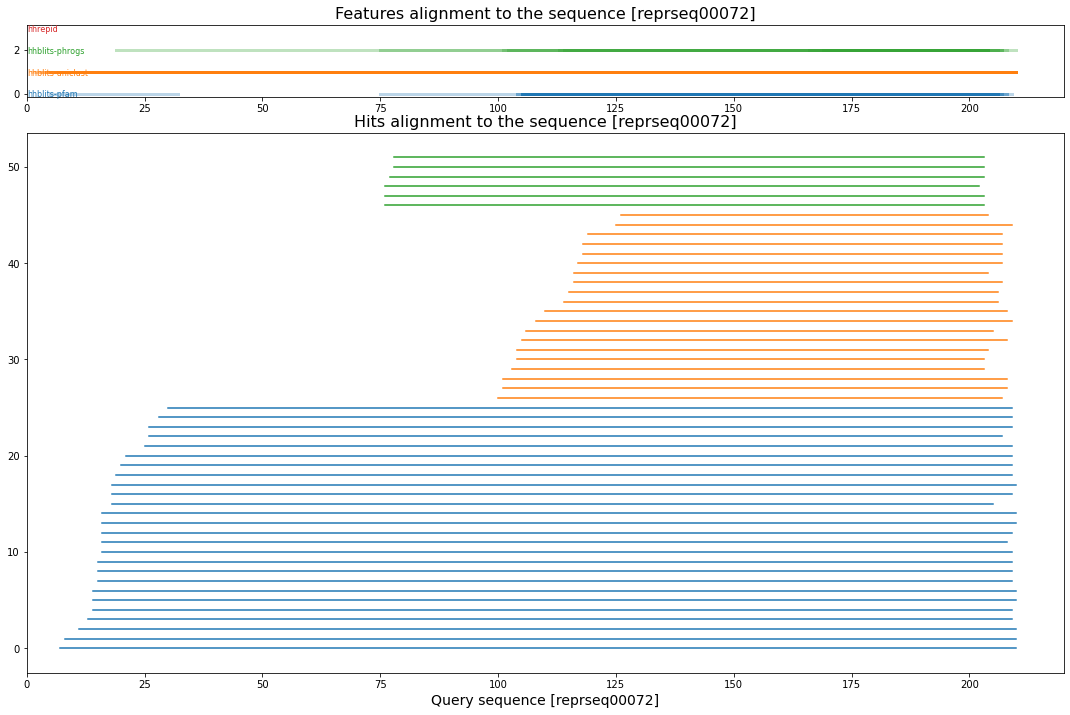

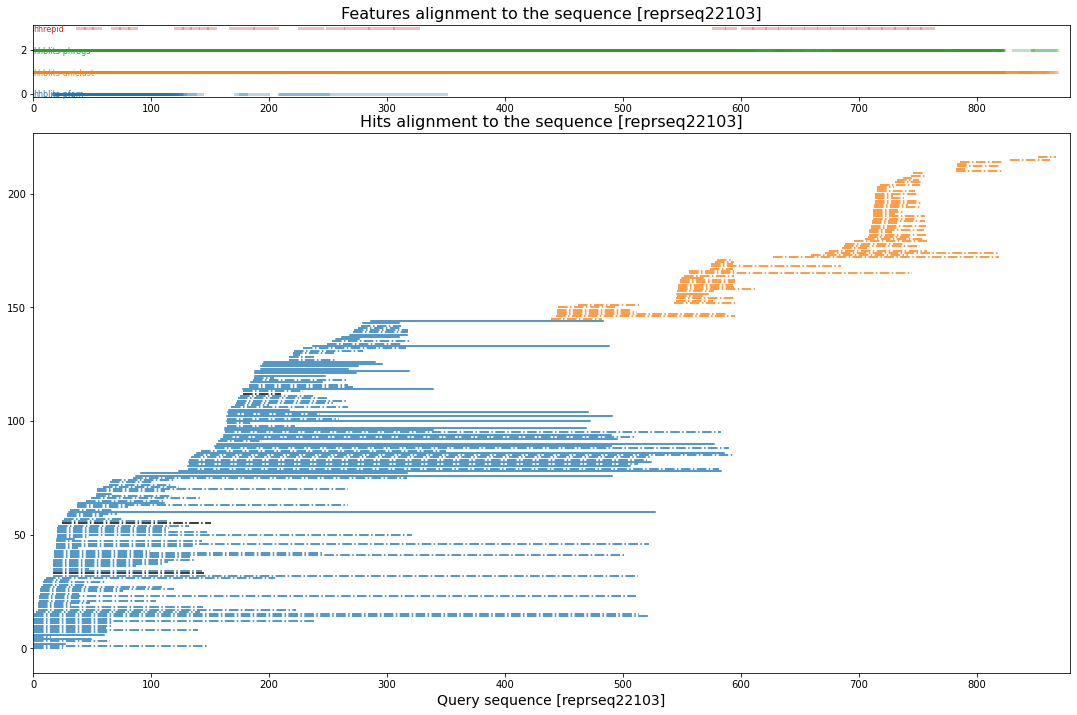

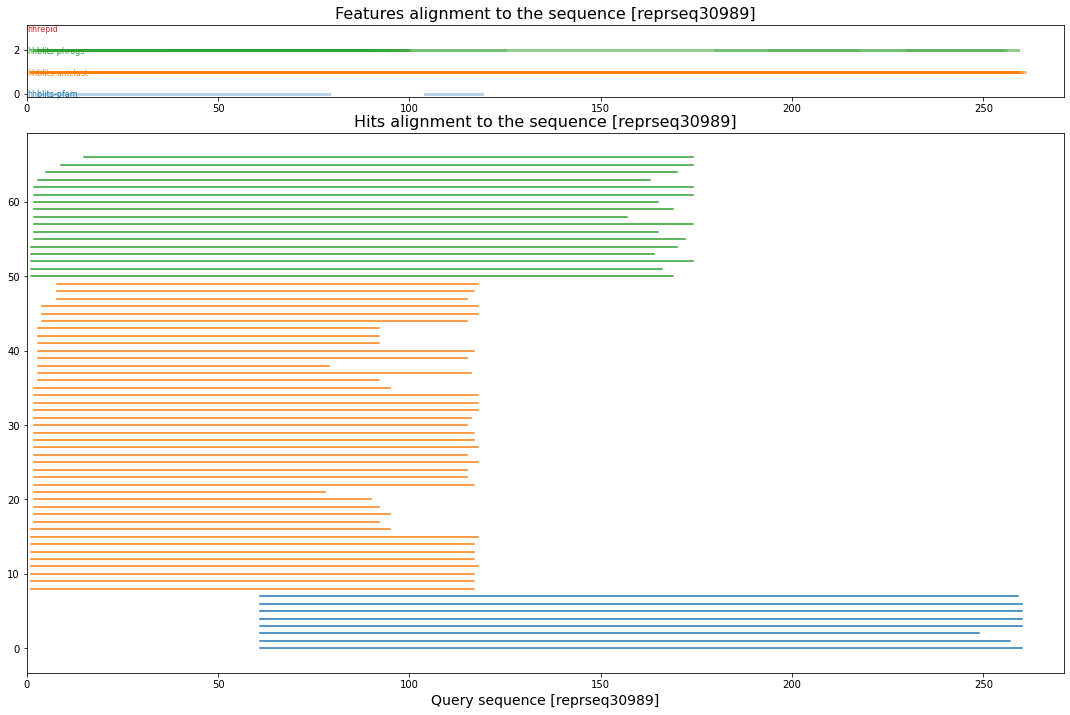

In [61]:
# plot required reprseqs
plot_alignment_selected(workdir_path, selected_reprseq_data, selected_features_data, save_figure=True)